# MEN 06 — Whisker-pad motion energy

The ME table (asset `e542022e`, aind-motion-energy 0.4.0 `rois_v2`) carries a second side-camera
trace: ME over a 110 × 80 px box on the whisker pad (`SideCameraRight_whiskerpad_box`), placed once
per group of sessions with the same framing. The box lies inside the side camera's frame, so the
side camera's whole-frame ME contains it. This notebook describes the whisker-pad trace next to the
two whole-frame traces.

0. Data
1. The box on one frame per mask group
2. One session, and whole-session r between the three traces
3. ME around the go cue, the choice, licks and lick-bout onsets
4. The `floor_sd` scale on the whisker-pad trace: the floor per session and across the session
5. Numbers

Sessions are those with a usable side camera (ME table and video screen, `men_01`); the bottom
camera is shown where it is usable in the same sessions. ME is on men_00's 100 Hz grid and on the
`floor_sd` scale (SDs above the session's 1st percentile, `men_03`), per session and trace.
Averages are taken within session, then within animal; plots show mean ± SEM across animals.

## Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import fip_utils as fu
import men_utils as mu
import signal_utils as su
import stats_utils as st
import behavior_utils as bu
import plot_utils as pu
import cue_me_maps as cm
from plotstyle import apply_style, style_ax, save_fig, PALETTE, OKABE_ITO

apply_style()
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="Degrees of freedom <= 0")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [2]:
IS_CO = os.path.isdir("/root/capsule")

# Same trial and event tables as men_00
ASSET_CANDIDATES = {
    "3ch": ["/root/capsule/data/DANE_3channels_curated",
            "../../data/results-a278f830-9bf2-48e8-9928-a2ff78e4818f"],
    "4ch": ["/root/capsule/data/DANE_4channels_curated",
            "../../data/results-ddcccb0f-f18f-44a6-a2b1-caba680d28a1"],
}
ME_DATA_ROOT = "/root/capsule/data" if IS_CO else os.environ.get("ME_DATA_ROOT", "../../data")
# men_00's cache layout; its own file, since the cache is keyed on the ME sources
CACHE_DIR = "/root/capsule/scratch/men_06" if IS_CO else os.environ.get("MEN06_CACHE", "../../data/men_06_cache")
CACHE_PATH = os.path.join(CACHE_DIR, "sessions.pkl")
FRAME_DIR = os.path.join(CACHE_DIR, "frames")   # one side-camera PNG per mask group
FIG_DIR = "/root/capsule/scratch/figures/men" if IS_CO else "../data/figures/men"
SAVE_FIG = True

# ── Data ─────────────────────────────────────────────────────────────────────
BOTTOM, SIDE, PAD = "BottomCamera", "SideCameraRight", "SideCameraRight:whiskerpad_box"
SOURCES = (BOTTOM, SIDE, PAD)
PAD_ROI_ID = f"{SIDE}_whiskerpad_box"   # the ROI's id in the table and in its mask file
FS = 100.0                # Hz, men_00's grid
ME_NORM = "floor_sd"
ME_UNIT = "SD above p1"
POST_LAST_CUE_S = 10.0    # the task span ends this long after the last go cue (men_05)

# ── Windows (s), as men_00 ───────────────────────────────────────────────────
CUE_LAGS = np.arange(-2.0, 5.0 + 1e-9, 1 / FS)
CHOICE_LAGS = np.arange(-1.0, 4.0 + 1e-9, 1 / FS)
LICK_LAGS = np.arange(-1.0, 1.0 + 1e-9, 1 / FS)
BOUT_LAGS = np.arange(-1.0, 3.0 + 1e-9, 1 / FS)
CUE_WIN = (0.0, 1.0)      # after the go cue
OUTCOME_WIN = (0.5, 2.0)  # after the choice

# ── Floor (men_03) ───────────────────────────────────────────────────────────
FLOOR_WIN_S = 60.0        # window for the floor
FLOOR_WIN_PCT = 5         # percentile of each window taken as its floor
MIN_SESSIONS_AT_T = 3     # per animal, for the floor across the session (as men_00 §6)

# ── Colors ───────────────────────────────────────────────────────────────────
SRC_LABEL = {BOTTOM: "bottom, whole frame", SIDE: "side, whole frame", PAD: "side, whisker pad"}
SRC_COLOR = {BOTTOM: "0.25", SIDE: OKABE_ITO["sky_blue"], PAD: OKABE_ITO["vermillion"]}
C_LICK = OKABE_ITO["bluish_green"]

## 0. Data

`mu.inventory_sessions` lists every session in the ME table with its trial and event tables. A
session is kept when its side camera is usable (status `ok` after the video screen); the whisker-pad
trace is then present, since every usable side camera carries it. The bottom camera is kept where its
own status is `ok`.

In [3]:
asset_roots = {name: root for name, cands in ASSET_CANDIDATES.items()
               if (root := fu.find_asset_root(cands))}
assert asset_roots, "no FIP asset found; check ASSET_CANDIDATES"
me_index = fu.load_me_index(ME_DATA_ROOT)
inv = mu.inventory_sessions(asset_roots, me_index)
inv = inv[inv["path"].notna() & (inv[f"{SIDE}_status"] == "ok")]
used = {(r.ses_idx, src): getattr(r, f"{mu.split_source(src)[0]}_status") == "ok"
        for r in inv.itertuples() for src in SOURCES}

sessions = mu.load_sessions(inv, fs=FS, cache_path=CACHE_PATH, data_root=ME_DATA_ROOT, cameras=SOURCES)
for s in sessions:
    s["me_n"] = {src: mu.normalise(x, ME_NORM) if x is not None and used[(s["session"], src)] else None
                 for src, x in s["me"].items()}
    tr = s["trials"]
    tr["responded"] = tr["animal_response"] != 2
    tr["next_cue"] = tr["goCue_start_time_in_session"].shift(-1)  # for censoring cue windows
    cues = tr["goCue_start_time_in_session"].dropna().to_numpy()
    s["span"] = (cues.min(), cues.max() + POST_LAST_CUE_S)
    n = len(s["me_n"][SIDE])
    s["in_span"] = su.interval_mask(n, s["t0"], FS, [s["span"][0]], [s["span"][1]])
assert all(s["me_n"][PAD] is not None for s in sessions)

SUBJECTS = sorted({s["subject"] for s in sessions})
coverage = pd.DataFrame([dict(subject=s["subject"], **{SRC_LABEL[src]: s["me_n"][src] is not None for src in SOURCES})
                         for s in sessions]).groupby("subject").sum()
print(f"{len(sessions)} sessions with the whisker pad, from {len(SUBJECTS)} animals; "
      f"{int(coverage[SRC_LABEL[BOTTOM]].sum())} with the bottom camera too")
coverage.T

loaded 64 sessions from cache ../../data/men_06_cache/sessions.pkl


64 sessions with the whisker pad, from 8 animals; 62 with the bottom camera too


subject,800886,808054,809491,815334,816212,816214,818585,818586
"bottom, whole frame",4,15,19,3,5,5,7,4
"side, whole frame",4,15,19,3,7,5,7,4
"side, whisker pad",4,15,19,3,7,5,7,4


## 1. The box on one frame per mask group

The box is placed once per mask group (`roi_masks` in the table's `index.csv`; `fu.load_roi_masks`).
For each group with a usable side camera: the middle frame of its first session's video, by frame
index (`video_clips.write_frames` from the MP4 on S3), with the box outlined. Groups whose cameras
the video screen excludes entirely are listed but not drawn.

In [4]:
from aind_dynamic_foraging_behavior_video_analysis.video_clips import write_frames

side_rows = me_index[me_index["camera"] == SIDE].copy()
side_rows["group"] = side_rows["roi_masks"].str.replace("rois_v2_", "").str.replace(f"_{SIDE}_masks.npz", "")
side_rows["usable"] = side_rows["ses_idx"].isin({s["session"] for s in sessions})
groups = side_rows.groupby("group").agg(sessions=("usable", "sum"),
                                        not_usable=("usable", lambda v: int((~v).sum())))
groups["mice"] = (side_rows[side_rows.usable].groupby("group")["subject"]
                  .agg(lambda v: ", ".join(sorted({str(x) for x in v}))))
groups

,sessions,not_usable,mice
group,,,
c0,44,5,"808054, 809491, 816212, 816214"
c0_l33,0,3,NaN
c15,10,0,"815334, 816212, 818585"
c30,1,0,818585
c30_l33,4,0,800886
c50,4,0,"818585, 818586"
c50_l33,1,18,818586


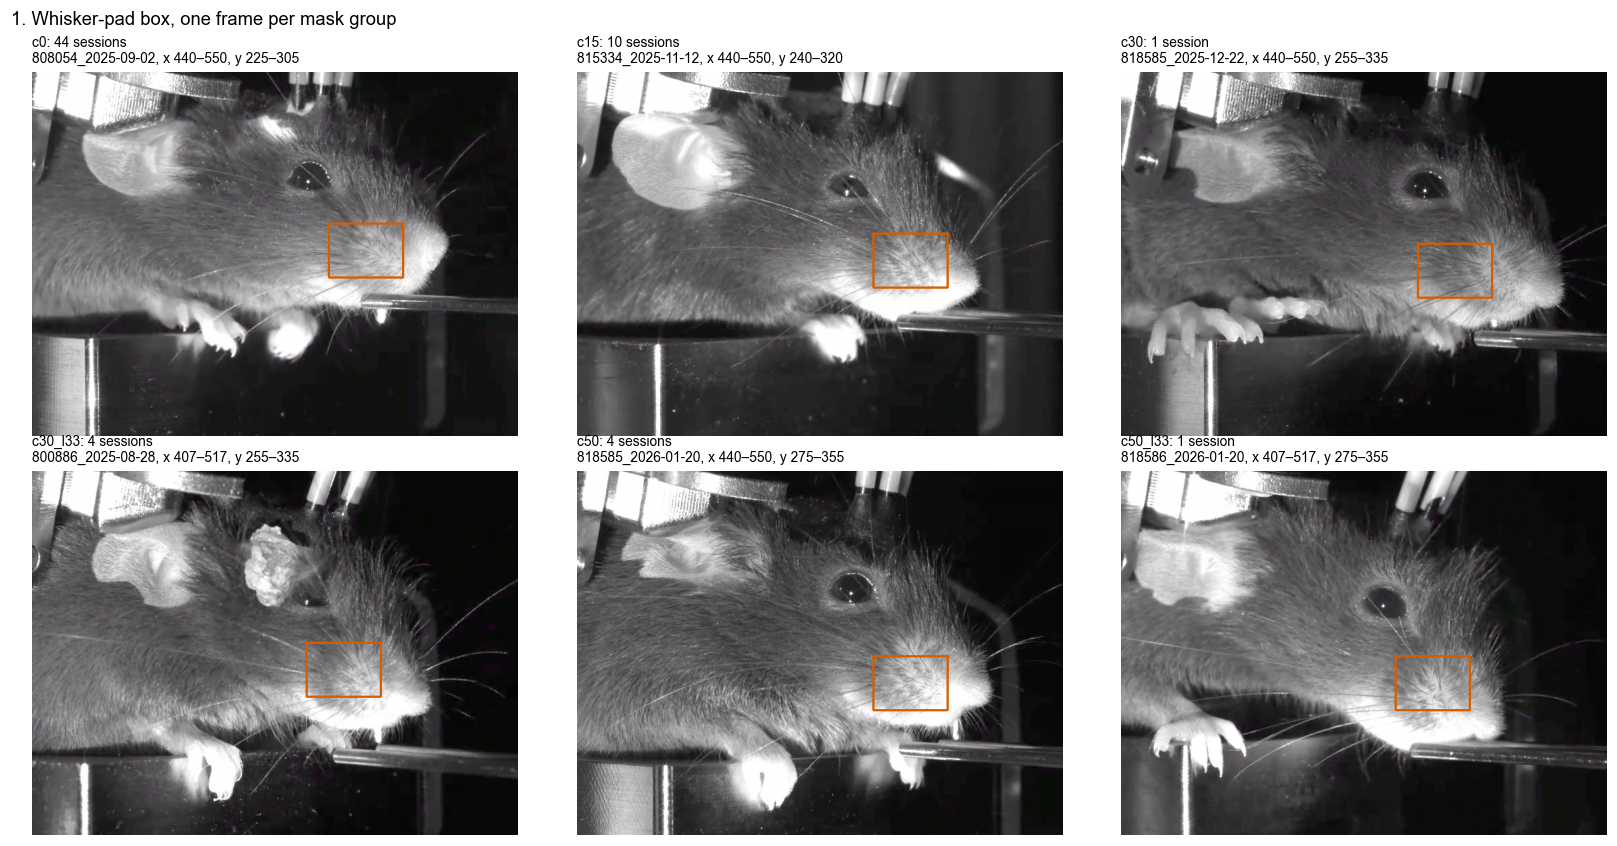

In [5]:
drawn = []
for name, rows in side_rows[side_rows.usable].sort_values("ses_idx").groupby("group"):
    row = rows.iloc[0]
    mask = fu.load_roi_masks(row["ses_idx"], SIDE, data_root=ME_DATA_ROOT)[PAD_ROI_ID]
    png = write_frames(cm.video_url(row), [int(row["n_frames"]) // 2], FRAME_DIR, row["ses_idx"])[0]
    ys, xs = np.nonzero(mask)
    drawn.append(dict(group=name, session=row["ses_idx"], png=png, mask=mask,
                      x=(xs.min(), xs.max() + 1), y=(ys.min(), ys.max() + 1)))

ncol = 3
nrow = int(np.ceil(len(drawn) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.9 * nrow))
for ax, d in zip(axes.flat, drawn):
    ax.imshow(plt.imread(d["png"]), cmap="gray")
    ax.contour(d["mask"], levels=[0.5], colors=[SRC_COLOR[PAD]], linewidths=1.5)
    n_ses = groups.loc[d["group"], "sessions"]
    ax.set_title(f"{d['group']}: {n_ses} session{'s' if n_ses != 1 else ''}\n"
                 f"{d['session']}, x {d['x'][0]}–{d['x'][1]}, y {d['y'][0]}–{d['y'][1]}",
                 loc="left", fontsize=9)
    ax.axis("off")
for ax in list(axes.flat)[len(drawn):]:
    ax.axis("off")
fig.suptitle("1. Whisker-pad box, one frame per mask group", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "men06_1_boxes", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 2. One session, and whole-session r

**a** 60 s of the three traces from the session with the median whisker pad × side r, with licks.
**b** Pearson r over the task span (first go cue to 10 s after the last) for each pair of traces, one
dot per session, by mouse. r does not depend on the per-session scale.

In [6]:
def masked_r(a, b, mask):
    if a is None or b is None:
        return np.nan
    ok = mask & np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(a[ok], b[ok])[0, 1] if ok.sum() > 30 * FS else np.nan


PAIRS = {"pad × side": (PAD, SIDE), "pad × bottom": (PAD, BOTTOM), "side × bottom": (SIDE, BOTTOM)}
PAIR_COLOR = {"pad × side": SRC_COLOR[SIDE], "pad × bottom": SRC_COLOR[BOTTOM], "side × bottom": OKABE_ITO["blue"]}
r_sess = pd.DataFrame([dict(subject=s["subject"], session=s["session"],
                            **{k: masked_r(s["me_n"][a], s["me_n"][b], s["in_span"]) for k, (a, b) in PAIRS.items()})
                       for s in sessions])
r_sess[list(PAIRS)].describe().round(3)

,pad × side,pad × bottom,side × bottom
count,64.000,62.000,62.000
mean,0.858,0.867,0.893
std,0.035,0.088,0.054
min,0.759,0.313,0.626
25%,0.842,0.872,0.877
50%,0.859,0.897,0.907
75%,0.887,0.908,0.925
max,0.913,0.931,0.950


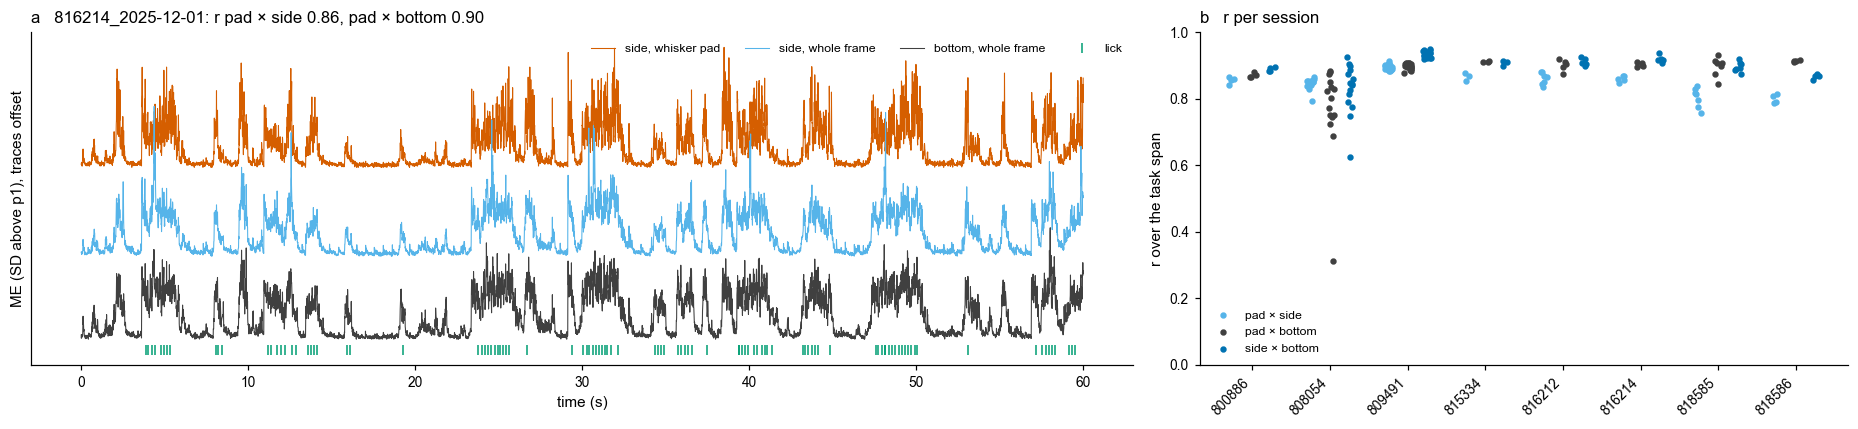

In [7]:
WIN_S = 60.0
order = r_sess["pad × side"].dropna().sort_values().index   # r_sess rows follow `sessions`
ex = sessions[order[len(order) // 2]]
ex_r = r_sess.loc[r_sess.session == ex["session"]].iloc[0]
t = ex["t0"] + np.arange(len(ex["me_n"][SIDE])) / FS
w0 = ex["span"][0] + 0.25 * (ex["span"][1] - ex["span"][0])
win = (t >= w0) & (t < w0 + WIN_S)

fig, axes = plt.subplots(1, 2, figsize=(17, 4), gridspec_kw=dict(width_ratios=[1.7, 1]))
ax = axes[0]
offset = 0.0
for src in (PAD, SIDE, BOTTOM):
    x = ex["me_n"][src]
    if x is None:
        continue
    ax.plot(t[win] - w0, x[win] + offset, color=SRC_COLOR[src], lw=0.7, label=SRC_LABEL[src])
    floor_next = offset
    offset -= np.nanpercentile(x[win], 99) * 1.05
licks = ex["licks"][(ex["licks"] >= w0) & (ex["licks"] < w0 + WIN_S)] - w0
ax.plot(licks, np.full(len(licks), floor_next - 0.5), "|", color=C_LICK, ms=6, label="lick")
ax.set(xlabel="time (s)", ylabel=f"ME ({ME_UNIT}), traces offset", yticks=[])
ax.set_title(f"a   {ex['session']}: r pad × side {ex_r['pad × side']:.2f}, pad × bottom {ex_r['pad × bottom']:.2f}",
             loc="left")
ax.legend(fontsize=8, ncol=4, loc="upper right")
style_ax(ax)

ax = axes[1]
rng = np.random.default_rng(0)
for j, (k, c) in enumerate(PAIR_COLOR.items()):
    for i, subj in enumerate(SUBJECTS):
        v = r_sess.loc[r_sess.subject == subj, k].dropna()
        ax.scatter(i + (j - 1) * 0.25 + (rng.random(len(v)) - 0.5) * 0.1, v, s=10, color=c,
                   label=k if i == 0 else None)
ax.set_xticks(range(len(SUBJECTS)), SUBJECTS, rotation=45, ha="right")
ax.set(ylabel="r over the task span", ylim=(0, 1))
ax.set_title("b   r per session", loc="left")
ax.legend(fontsize=8, loc="lower left")
style_ax(ax)
fig.tight_layout()
save_fig(fig, "men06_2_example_r", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 3. ME around the go cue, the choice, licks and lick-bout onsets

Each trace on its own `floor_sd` scale, so amplitudes are in that trace's session SDs.
**Go cue:** all trials, cut at the next go cue. **Choice:** responded trials (the first lick after the
go cue). **Lick:** every lick, either spout (`mu.lick_clock_check`). **Lick-bout onset:** the first lick
of each bout (`bu.lick_bouts`: a gap over 0.7 s starts a new bout) in the task span. Top row: the three
traces, mean ± SEM across animals. Bottom row: the whisker pad, each animal.

In [8]:
def aligned(src, times_fn, lags, censor_fn=None):
    # one session-mean trace per session for one source; [(subject, trace)]
    out = []
    for s in sessions:
        x = s["me_n"][src]
        if x is None:
            continue
        times = times_fn(s)
        if len(times) < 3:
            continue
        seg = su.peri_event_grid(x, s["t0"], FS, times, lags,
                                 censor_after=censor_fn(s) if censor_fn else None)
        out.append((s["subject"], np.nanmean(seg, axis=0)))
    return out


def bout_onsets(s):
    b = bu.lick_bouts(s["lick_events"])
    on = b["onset"].to_numpy(float)
    return on[(on >= s["span"][0]) & (on < s["span"][1])]


ALIGN = {
    "go cue": (lambda s: s["trials"]["goCue_start_time_in_session"].to_numpy(float), CUE_LAGS,
               lambda s: s["trials"]["next_cue"].to_numpy(float)),
    "choice": (lambda s: s["trials"].loc[s["trials"]["responded"], "choice_time_in_session"].dropna().to_numpy(float),
               CHOICE_LAGS, None),
    "lick": (lambda s: s["licks"], LICK_LAGS, None),
    "lick-bout onset": (bout_onsets, BOUT_LAGS, None),
}
aligned_tr = {name: {src: aligned(src, fn, lags, cens) for src in SOURCES}
              for name, (fn, lags, cens) in ALIGN.items()}
anim_tr = {name: {src: st.group_means([t for _, t in v], [g for g, _ in v]) for src, v in d.items()}
           for name, d in aligned_tr.items()}

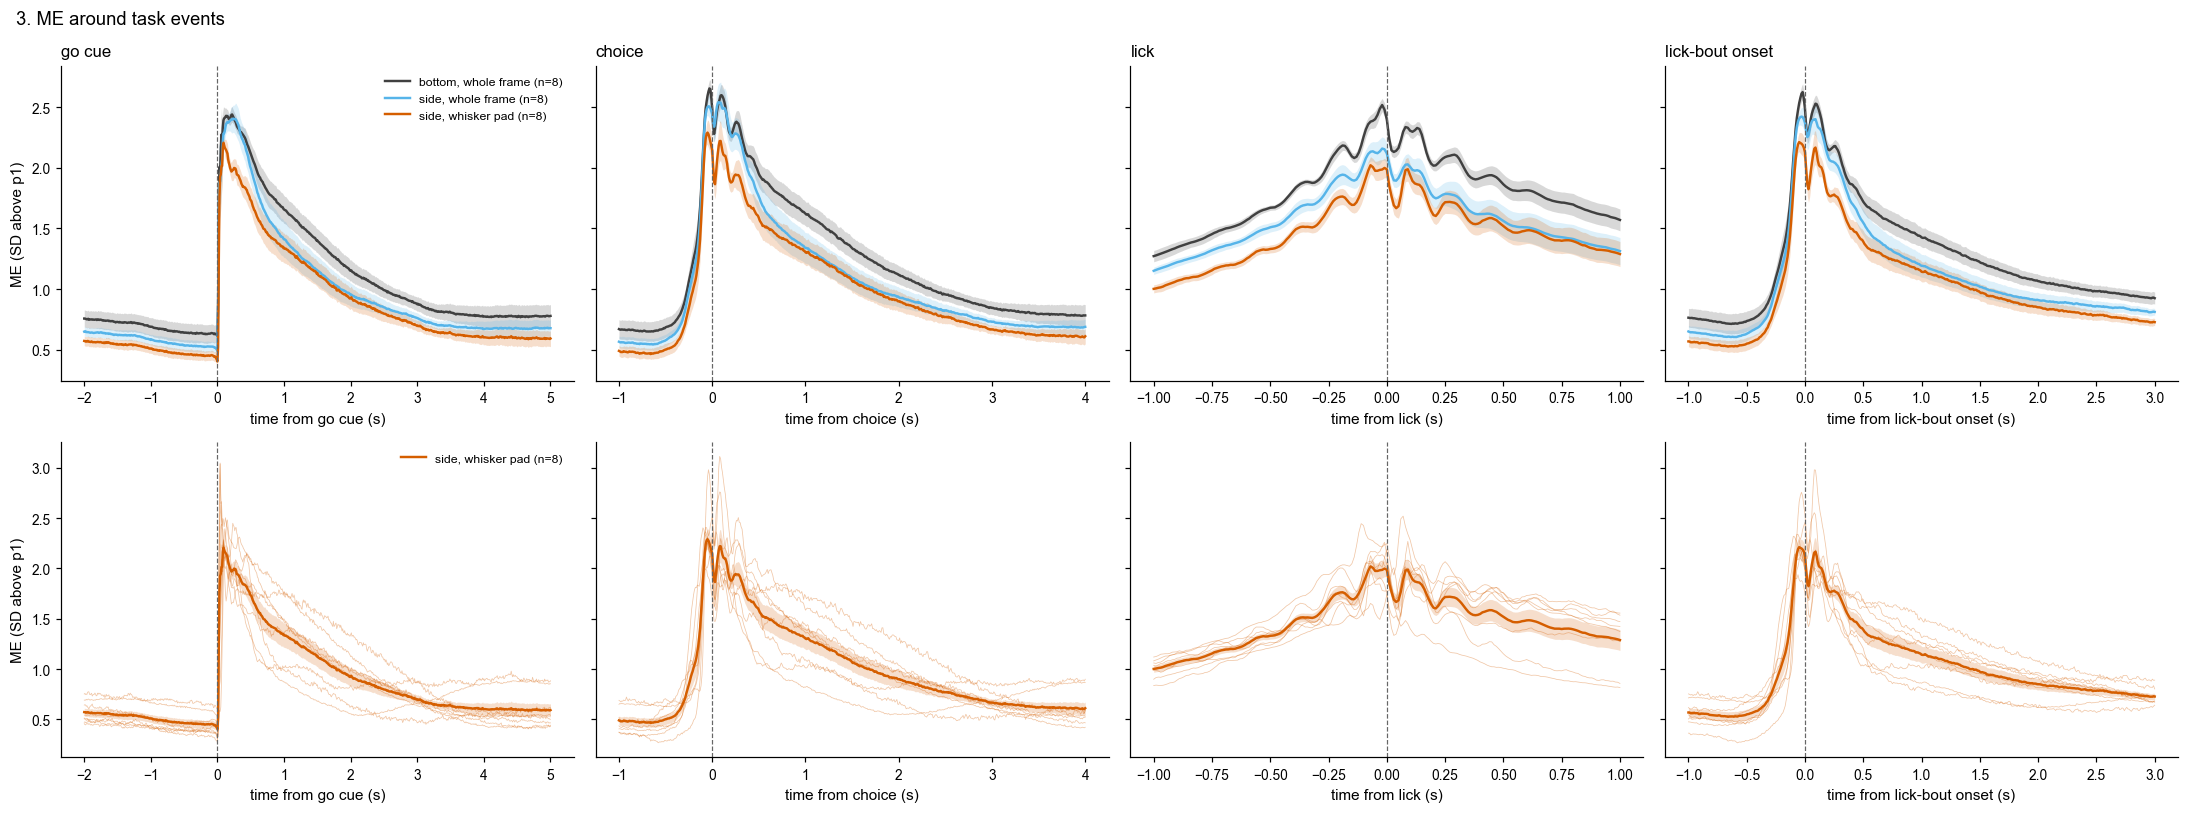

In [9]:
fig, axes = plt.subplots(2, len(ALIGN), figsize=(5 * len(ALIGN), 7.5), sharey="row")
for j, (name, (_, lags, _)) in enumerate(ALIGN.items()):
    ax = axes[0, j]
    for src in SOURCES:
        pu.plot_mean_sem(ax, lags, anim_tr[name][src][1], SRC_COLOR[src], SRC_LABEL[src], label_n=True)
    ax.set_title(name, loc="left")
    ax = axes[1, j]
    pu.plot_mean_sem(ax, lags, anim_tr[name][PAD][1], SRC_COLOR[PAD], SRC_LABEL[PAD], show_rows=True, label_n=True)
    for ax in axes[:, j]:
        ax.axvline(0, color=PALETTE["neutral"], ls="--", lw=0.8)
        ax.set_xlabel(f"time from {name} (s)")
        style_ax(ax)
for ax in axes[:, 0]:
    ax.set_ylabel(f"ME ({ME_UNIT})")
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
fig.suptitle("3. ME around task events", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "men06_3_task_events", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

Per animal: the lick-triggered peak lag of each trace (its clock check, as `men_00` §0), mean ME
0–1 s after the go cue, and mean ME 0.5–2 s after the choice.

In [10]:
clock, _ = mu.lick_clock_check(sessions, SOURCES, FS, LICK_LAGS)
rows = []
for s in sessions:
    tr = s["trials"]
    resp = tr["responded"].to_numpy(bool) & tr["choice_time_in_session"].notna().to_numpy()
    for src in SOURCES:
        x = s["me_n"][src]
        if x is None:
            continue
        rows.append(dict(subject=s["subject"], session=s["session"], source=SRC_LABEL[src],
                         cue_me=np.nanmean(su.window_mean_grid(x, s["t0"], FS, tr["goCue_start_time_in_session"], *CUE_WIN)),
                         choice_me=np.nanmean(su.window_mean_grid(x, s["t0"], FS, tr.loc[resp, "choice_time_in_session"], *OUTCOME_WIN))))
levels = pd.DataFrame(rows).merge(clock.assign(source=clock["camera"].map(SRC_LABEL))[["session", "source", "peak_lag_s"]],
                                  on=["session", "source"])
level_anim = (levels.groupby(["subject", "source"])[["peak_lag_s", "cue_me", "choice_me"]].mean()
              .unstack("source").reindex(columns=[SRC_LABEL[s] for s in SOURCES], level="source"))
level_anim.round(3)

peak_lag_s                                                  cue_me                                               choice_me                                    
source  bottom, whole frame side, whole frame side, whisker pad bottom, whole frame side, whole frame side, whisker pad bottom, whole frame side, whole frame side, whisker pad
subject                                                                                                                                                                        
800886               -0.017            -0.067             0.023               1.735             1.605             1.403               1.118             0.880             0.939
808054               -0.007            -0.072            -0.004               2.034             1.587             1.483               1.288             0.775             0.757
809491               -0.049            -0.031             0.061               2.112             2.058             1.930               1.394             1.371             1.260
815334               -0.037            -0.050            -0.030               1.869             1.778             1.614               1.326             0.999             0.988
816212               -0.014            -0.026            -0.050               2.262             2.033             1.811               1.626             1.325             1.292
816214               -0.024            -0.044            -0.008               1.952             1.808             1.613               1.499             1.339             1.280
818585               -0.010            -0.013             0.089               2.318             2.347             1.922               1.808             1.695             1.494
818586               -0.025             0.045             0.180               2.024             2.072             1.698               1.894             1.580             1.602

## 4. The `floor_sd` scale on the whisker-pad trace

`floor_sd` is max(0, ME − p1) / SD per session. It was chosen on bottom-camera whole-frame ME (`men_03`),
where p1 sits just below the level the mouse holds when still, so 0 means still in every session. The
same measures on each trace, from the 100 Hz grid: the trace is cut into 60 s windows and the 5th
percentile of each window (its quietest 3 s) is that window's floor.

**a** The session's floor (median over windows) on the `floor_sd` scale: where stillness sits above 0.
**b** The floor in raw ME ÷ session SD: where stillness sits above no pixel change. **c** How much the
floor moves across the session (90th − 10th percentile over windows, session SDs). **d** The window
floors on the `floor_sd` scale against minutes from the first go cue, averaged within and then
across animals.

In [11]:
def window_floors(x):
    # floor of each FLOOR_WIN_S window (its FLOOR_WIN_PCT-th percentile); NaN if under half the window is finite
    n = int(FLOOR_WIN_S * FS)
    w = x[: len(x) // n * n].reshape(-1, n)
    f = np.nanpercentile(w, FLOOR_WIN_PCT, axis=1)
    f[np.isfinite(w).sum(1) < n / 2] = np.nan
    return f


floor_rows, floor_tc = [], {src: [] for src in SOURCES}
for s in sessions:
    for src in SOURCES:
        x = s["me_n"][src]
        if x is None:
            continue
        raw = s["me"][src].astype(float)
        sd = np.nanstd(raw, ddof=1)
        w = window_floors(x)
        floor_rows.append(dict(subject=s["subject"], session=s["session"], source=SRC_LABEL[src],
                               floor=np.nanmedian(w), floor_raw_sd=np.nanmedian(window_floors(raw)) / sd,
                               floor_range=np.nanpercentile(w, 90) - np.nanpercentile(w, 10)))
        t_mid = s["t0"] + (np.arange(len(w)) + 0.5) * FLOOR_WIN_S - s["span"][0]
        floor_tc[src].append((s["subject"], t_mid, w))
floors = pd.DataFrame(floor_rows)
floors.groupby("source")[["floor", "floor_raw_sd", "floor_range"]].describe().T.round(3)

source              bottom, whole frame  side, whisker pad  side, whole frame
floor        count               62.000             64.000             64.000
             mean                 0.071              0.051              0.064
             std                  0.029              0.008              0.015
             min                  0.041              0.031              0.036
             25%                  0.055              0.046              0.054
             50%                  0.066              0.051              0.061
             75%                  0.080              0.056              0.071
             max                  0.262              0.075              0.120
floor_raw_sd count               62.000             64.000             64.000
             mean                 0.331              0.238              0.338
             std                  0.081              0.044              0.062
             min                  0.204              0.144              0.145
             25%                  0.283              0.209              0.301
             50%                  0.316              0.246              0.339
             75%                  0.356              0.265              0.374
             max                  0.666              0.324              0.526
floor_range  count               62.000             64.000             64.000
             mean                 0.077              0.046              0.071
             std                  0.025              0.016              0.027
             min                  0.030              0.018              0.029
             25%                  0.063              0.035              0.048
             50%                  0.075              0.043              0.072
             75%                  0.090              0.057              0.089
             max                  0.168              0.104              0.168

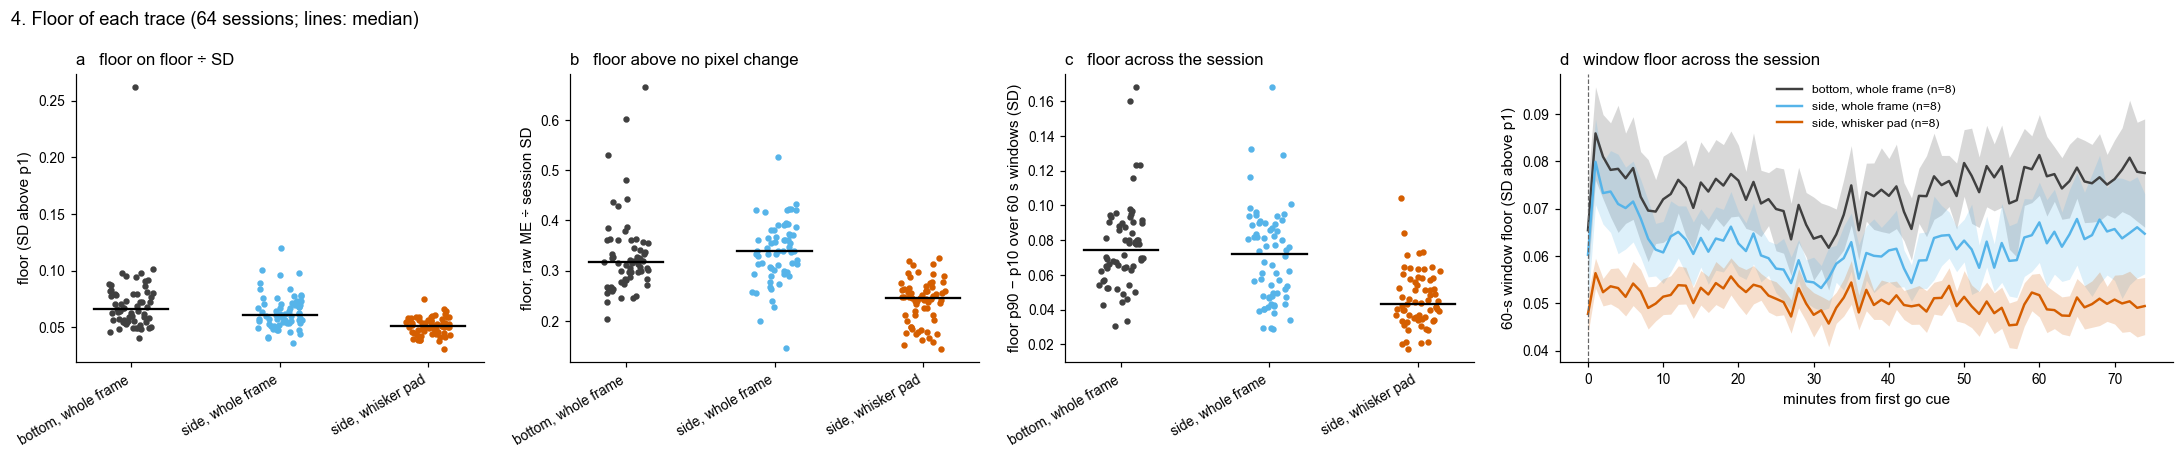

In [12]:
T_GRID = np.arange(-FLOOR_WIN_S, 120 * 60, FLOOR_WIN_S)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.5]))
rng = np.random.default_rng(0)
for ax, col, ylabel, title in (
        (axes[0], "floor", f"floor ({ME_UNIT})", "a   floor on floor ÷ SD"),
        (axes[1], "floor_raw_sd", "floor, raw ME ÷ session SD", "b   floor above no pixel change"),
        (axes[2], "floor_range", "floor p90 − p10 over 60 s windows (SD)", "c   floor across the session")):
    for k, src in enumerate(SOURCES):
        v = floors.loc[floors.source == SRC_LABEL[src], col]
        ax.scatter(k + (rng.random(len(v)) - 0.5) * 0.3, v, s=10, color=SRC_COLOR[src])
        ax.plot([k - 0.25, k + 0.25], [v.median()] * 2, color="k", lw=1.5)
    ax.set_xticks(range(len(SOURCES)), [SRC_LABEL[s] for s in SOURCES], rotation=30, ha="right")
    ax.set(ylabel=ylabel)
    ax.set_title(title, loc="left")
    style_ax(ax)
ax = axes[3]
for src in SOURCES:
    arr = mu.per_animal_timecourse(floor_tc[src], T_GRID, MIN_SESSIONS_AT_T)
    pu.plot_mean_sem(ax, T_GRID / 60, arr, SRC_COLOR[src], SRC_LABEL[src], label_n=True)
ax.axvline(0, color=PALETTE["neutral"], ls="--", lw=0.8)
ax.set(xlabel="minutes from first go cue", ylabel=f"60-s window floor ({ME_UNIT})")
ax.set_title("d   window floor across the session", loc="left")
ax.legend(fontsize=8)
style_ax(ax)
fig.suptitle(f"4. Floor of each trace ({len(sessions)} sessions; lines: median)", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "men06_4_floor", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

The whisker-pad sessions with the lowest, median and highest floor on the `floor_sd` scale: 60 s from
the middle of the task span. Dashed: the session's floor; dotted: 0.

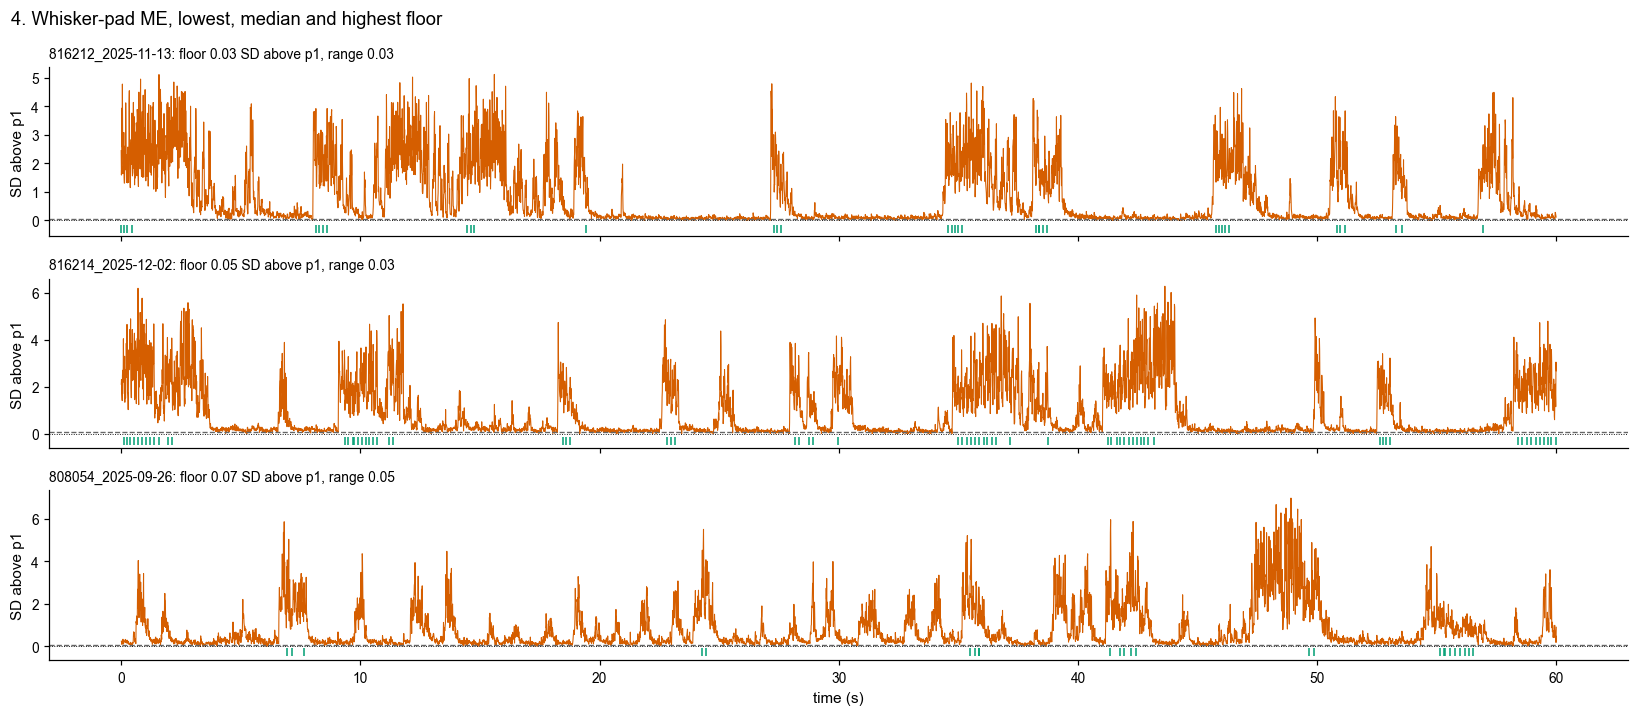

In [13]:
pad_f = floors[floors.source == SRC_LABEL[PAD]].sort_values("floor").reset_index(drop=True)
picks = [pad_f.iloc[0], pad_f.iloc[len(pad_f) // 2], pad_f.iloc[-1]]
by_session = {s["session"]: s for s in sessions}

fig, axes = plt.subplots(len(picks), 1, figsize=(15, 2.2 * len(picks)), sharex=True)
for ax, row in zip(axes, picks):
    s = by_session[row["session"]]
    x = s["me_n"][PAD]
    t = s["t0"] + np.arange(len(x)) / FS
    mid = 0.5 * (s["span"][0] + s["span"][1])
    win = (t >= mid) & (t < mid + WIN_S)
    ax.plot(t[win] - mid, x[win], color=SRC_COLOR[PAD], lw=0.7)
    ax.axhline(row["floor"], color="0.4", lw=0.9, ls="--")
    ax.axhline(0, color="k", lw=0.6, ls=":")
    licks = s["licks"][(s["licks"] >= mid) & (s["licks"] < mid + WIN_S)] - mid
    ax.plot(licks, np.full(len(licks), -0.3), "|", color=C_LICK, ms=5)
    ax.set_ylabel(ME_UNIT)
    ax.set_title(f"{row['session']}: floor {row['floor']:.2f} SD above p1, range {row['floor_range']:.2f}",
                 loc="left", fontsize=9)
    style_ax(ax)
axes[-1].set_xlabel("time (s)")
fig.suptitle("4. Whisker-pad ME, lowest, median and highest floor", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "men06_4_floor_examples", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 5. Numbers

Mean ± SEM across animals (sessions averaged within animal first).

In [14]:
def describe(v):
    v = pd.Series(v).dropna()
    return f"{v.mean():.3f} ± {v.sem():.3f} (n={len(v)})"


r_anim = r_sess.groupby("subject")[list(PAIRS)].mean()
floor_anim = floors.groupby(["subject", "source"])[["floor", "floor_raw_sd", "floor_range"]].mean().unstack("source")
summary = [(f"r {k}, task span", describe(r_anim[k])) for k in PAIRS]
for src in SOURCES:
    lab = SRC_LABEL[src]
    summary += [
        (f"{lab}: lick-triggered peak lag (s)", describe(level_anim[("peak_lag_s", lab)])),
        (f"{lab}: ME {CUE_WIN[0]:g}–{CUE_WIN[1]:g} s after go cue ({ME_UNIT})", describe(level_anim[("cue_me", lab)])),
        (f"{lab}: ME {OUTCOME_WIN[0]:g}–{OUTCOME_WIN[1]:g} s after choice ({ME_UNIT})", describe(level_anim[("choice_me", lab)])),
        (f"{lab}: floor ({ME_UNIT})", describe(floor_anim[("floor", lab)])),
        (f"{lab}: floor, raw ÷ SD", describe(floor_anim[("floor_raw_sd", lab)])),
        (f"{lab}: floor p90 − p10 across the session (SD)", describe(floor_anim[("floor_range", lab)])),
    ]
pd.DataFrame(summary, columns=["quantity", "mean ± SEM across animals"])

,quantity,mean ± SEM across animals
0,"r pad × side, task span",0.849 ± 0.011 (n=8)
1,"r pad × bottom, task span",0.883 ± 0.017 (n=8)
2,"r side × bottom, task span",0.894 ± 0.012 (n=8)
3,"bottom, whole frame: lick-triggered peak lag (s)",-0.023 ± 0.005 (n=8)
4,"bottom, whole frame: ME 0–1 s after go cue (SD...",2.038 ± 0.068 (n=8)
5,"bottom, whole frame: ME 0.5–2 s after choice (...",1.494 ± 0.094 (n=8)
6,"bottom, whole frame: floor (SD above p1)",0.071 ± 0.006 (n=8)
7,"bottom, whole frame: floor, raw ÷ SD",0.345 ± 0.018 (n=8)
8,"bottom, whole frame: floor p90 − p10 across th...",0.071 ± 0.006 (n=8)
9,"side, whole frame: lick-triggered peak lag (s)",-0.032 ± 0.013 (n=8)
